# What Makes a GitHub Repo Popular?

This notebook explores **4,000 GitHub repositories** sampled through the GitHub REST API (snapshot of
8 October 2026) to see which factors go together with the number of stars a repository has.

It answers five questions, in order:

1. Which programming languages are most popular, and how has that changed over the years?
2. Are README length, images/GIFs, badges and structure related to stars?
3. Is commit activity related to popularity, and how many popular repos are actually inactive?
4. How long does it take a repo to reach 100, 1,000 or 10,000 stars?
5. Which licences and topics are most common among popular repos, and which topics are rising?

**How to read the numbers.** The sample is *stratified*. It contains 1,000 repos from each star
bucket (10–99, 100–999, 1k–9.9k and 10k+ stars), spread evenly over creation years 2012–2025 and
13 language groups. On GitHub, unpopular repos vastly outnumber popular ones, so the sample is
deliberately **not** representative of GitHub as a whole. Three tools keep the conclusions honest:

- **Comparisons within a star bucket**, which are fair because each bucket is sampled the same way.
- **Population weights.** The collector also recorded how many repos exist in every stratum (the
  *census*), so each sampled repo can be weighted by how many GitHub repos it stands for.
- **The census itself**, for population-level trends such as language popularity over time.

Everything here describes **associations, not causes**. Section 10 lists the limitations.

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # make the project's `wgs` package importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

from wgs import analysis as A

A.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

data = A.load()
repos = data.repos.copy()
repos["weight"] = A.stratum_weights(repos, data.population)
BUCKETS = A.BUCKET_ORDER
LABEL = A.BUCKET_LABELS
print(f"{len(repos):,} repos, snapshot {data.report['snapshot']}, "
      f"standing for {repos['weight'].sum():,.0f} GitHub repos with 10+ stars created 2012-2025")

4,000 repos, snapshot 2026-10-08, standing for 2,610,140 GitHub repos with 10+ stars created 2012-2025


## 1. Data overview

In [2]:
overview = repos.groupby("bucket", observed=True).agg(
    repos=("id", "size"),
    median_stars=("stars", "median"),
    median_forks=("forks", "median"),
    median_age_years=("age_days", lambda s: s.median() / 365.25),
    with_readme=("readme_format", lambda s: (s != "none").mean()),
    list_repos=("is_list_repo", "sum"),
    population=("weight", "sum"),
)
overview.rename(index=LABEL)

,repos,median_stars,median_forks,median_age_years,with_readme,list_repos,population
bucket,,,,,,,
10–99,1000,18.0,4.0,7.830,0.958,4,2.172e+06
100–999,1000,168.0,34.0,7.776,0.989,11,3.790e+05
1k–9.9k,1000,1755.0,221.0,7.867,0.997,29,5.387e+04
10k+,1000,16763.5,2067.5,8.453,1.000,56,4.948e+03


The four buckets are equal in the sample but very unequal on GitHub. The census says repos with
10–99 stars outnumber 10k+ repos by about 440 to 1, so any "overall" average over the raw
sample would really be an average of four very different populations. The analysis below either
compares buckets side by side or uses the population weights.

In [3]:
report = {k: v for k, v in data.report.items() if k not in ("columns_with_nulls",)}
pd.Series(report, dtype=object).to_frame("build report")

,build report
snapshot,2026-10-08
rows,4000
rows_per_bucket,"{'10-100': 1000, '100-1k': 1000, '1k-10k': 100..."
duplicate_ids,0
negative_age,0
negative_days_since_push,0
stars_drifted_out_of_bucket,0
readme_missing,56
commit_stats_missing,5
list_repos,100


## 2. Cleaning

The build pipeline (`python -m wgs.features.build`) already validated the data: no duplicates, no
negative ages, and every repo still inside its star bucket. This section decides what each
analysis leaves out, and how to deal with very skewed numbers.

In [4]:
software = repos[(repos["readme_format"] != "none") & ~repos["is_list_repo"]]
reliable = repos[repos["history_reliable"]]

pd.Series({
    "all repos": len(repos),
    "awesome lists / link collections (excluded from README analysis)": int(repos["is_list_repo"].sum()),
    "no README (excluded from README analysis)": int((repos["readme_format"] == "none").sum()),
    "repos used for README analysis": len(software),
    "commit statistics unavailable": int(repos["commits_52w"].isna().sum()),
    "repos with GH Archive star history": int(repos["coverage"].notna().sum()),
    "...of which reliable (coverage 0.5-1.5)": len(reliable),
}).to_frame("count")

,count
all repos,4000
awesome lists / link collections (excluded from README analysis),100
no README (excluded from README analysis),56
repos used for README analysis,3844
commit statistics unavailable,5
repos with GH Archive star history,2984
...of which reliable (coverage 0.5-1.5),2468


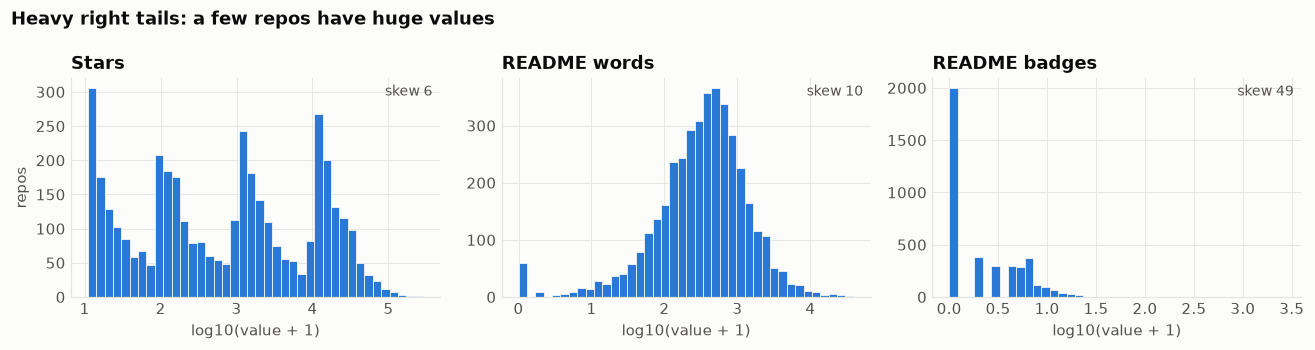

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, title in zip(
    axes,
    ["stars", "readme_words", "readme_badges"],
    ["Stars", "README words", "README badges"],
):
    values = repos[col].dropna()
    ax.hist(np.log10(values + 1), bins=40, color=A.CATEGORICAL[0], edgecolor=A.SURFACE, linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel("log10(value + 1)")
    ax.set_ylabel("repos" if col == "stars" else "")
    ax.text(0.98, 0.92, f"skew {stats.skew(values):.0f}", transform=ax.transAxes, ha="right",
            color=A.INK["secondary"], fontsize=9)
fig.suptitle("Heavy right tails: a few repos have huge values", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

(The star histogram has four humps because the sample takes 1,000 repos from each star bucket.)

Stars, README length and badge counts all have very long right tails. Most extreme values belong
to *awesome lists*, such as a list with over 2,600 badges. Instead of deleting outliers, the
analysis uses methods that do not depend on raw magnitudes:

- **Medians**, never means.
- **Log scales** in charts.
- **Spearman rank correlation**, which only looks at order, so one giant repo cannot dominate it.
- **Awesome lists left out** of the README analysis, because a README that *is* a list of links
  says nothing about how a project presents itself.

## 3. Languages: what is popular, and how has it changed?

The census gives the number of GitHub repos with 10+ stars for every star bucket × creation year ×
language group, so these trends come from the **full population**, not from the balanced sample.

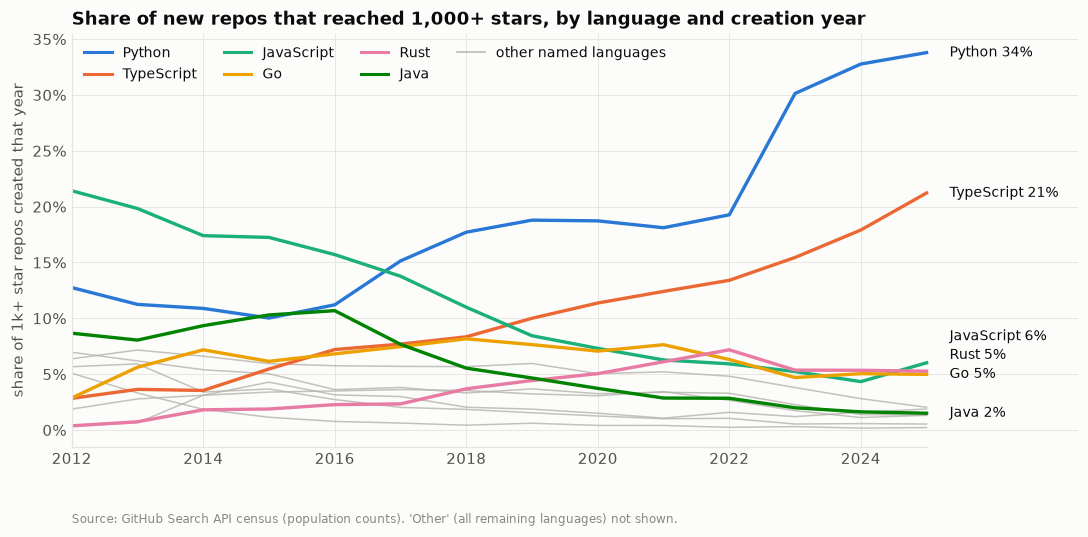

In [6]:
pop = data.population
popular = pop[pop["bucket"].isin(["1k-10k", "10k+"])]
by_year = popular.groupby(["year", "lang_group"])["population"].sum().unstack()
share = by_year.div(by_year.sum(axis=1), axis=0) * 100

highlight = ["Python", "TypeScript", "JavaScript", "Go", "Rust", "Java"]
colors = dict(zip(highlight, A.CATEGORICAL))

fig, ax = plt.subplots(figsize=(10, 5))
for lang in share.columns:
    if lang in highlight or lang == "Other":
        continue
    ax.plot(share.index, share[lang], color=A.MUTED, linewidth=1, alpha=0.8)
for lang in highlight:
    ax.plot(share.index, share[lang], color=colors[lang], linewidth=2.2)

# End labels, nudged apart vertically so close values do not overlap.
last_year = share.index[-1]
placed = []
for value, lang in sorted((share[l].iloc[-1], l) for l in highlight):
    y = value if not placed else max(value, placed[-1] + 1.7)
    placed.append(y)
    ax.annotate(f"{lang} {value:.0f}%", xy=(last_year, value), xytext=(last_year + 0.35, y),
                textcoords="data", va="center", fontsize=9, color=A.INK["primary"])
ax.set_xlim(share.index[0], last_year + 2.3)
ax.set_xticks(range(share.index[0], last_year + 1, 2))
ax.spines["bottom"].set_bounds(share.index[0], last_year)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title("Share of new repos that reached 1,000+ stars, by language and creation year")
ax.set_ylabel("share of 1k+ star repos created that year")
ax.legend(handles=[plt.Line2D([], [], color=colors[l], label=l) for l in highlight]
          + [plt.Line2D([], [], color=A.MUTED, linewidth=1, label="other named languages")],
          ncol=4, loc="upper left", fontsize=9)
A.note(ax, "Source: GitHub Search API census (population counts). 'Other' (all remaining languages) not shown.")
fig.tight_layout()

In [7]:
(share.loc[[2012, 2016, 2020, 2024, 2025]].T.sort_values(2025, ascending=False)).round(1)

year,2012,2016,2020,2024,2025
lang_group,,,,,
Python,12.8,11.2,18.7,32.8,33.8
TypeScript,2.8,7.2,11.4,17.9,21.2
Other,24.8,26.6,32.2,25.3,19.9
JavaScript,21.4,15.7,7.3,4.3,6.0
Rust,0.4,2.3,5.0,5.3,5.3
Go,2.9,6.8,7.1,5.0,5.0
C++,6.4,5.8,5.0,2.8,2.0
Swift,0.3,3.1,1.5,1.6,1.9
Java,8.7,10.7,3.7,1.6,1.5


**Python and TypeScript took over.** Among repos that went on to collect 1,000+ stars, Python's
share grew from about 13% of repos created in 2012 to about 34% of those created in 2025.
TypeScript grew from about 3% to 21%. JavaScript fell from about 21% to 6%, and Java, PHP and Ruby
each dropped to 2% or less. Rust and Go rose quickly in the mid-2010s and have stayed at about 5%
each since.

Raw counts mix two things, though: how many repos are written in a language, and how often those
repos become popular. The **hit rate** below separates the second one. Of all repos in a language
that collected at least 10 stars, what fraction reached 1,000?

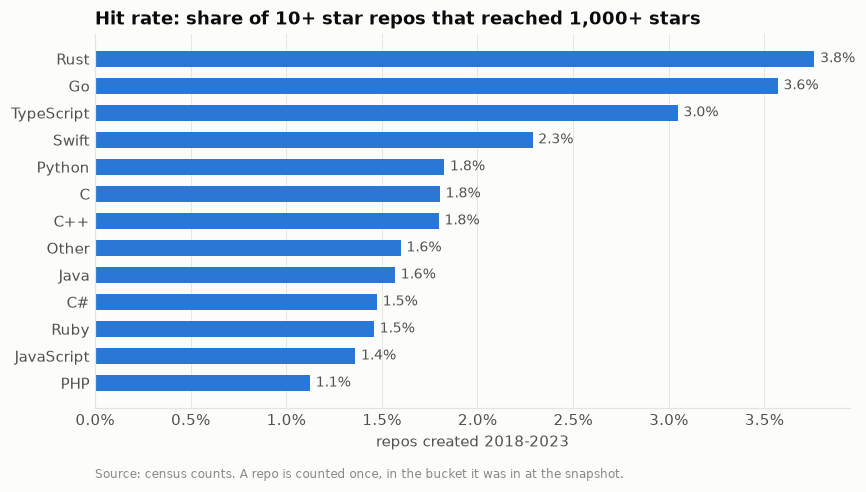

In [8]:
recent = pop[pop["year"].between(2018, 2023)]  # old enough to have had time to grow
totals = recent.groupby("lang_group")["population"].sum()
hits = recent[recent["bucket"].isin(["1k-10k", "10k+"])].groupby("lang_group")["population"].sum()
hit_rate = (hits / totals * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(hit_rate.index, hit_rate.values, color=A.CATEGORICAL[0], height=0.6)
for y, v in enumerate(hit_rate.values):
    ax.text(v + 0.03, y, f"{v:.1f}%", va="center", fontsize=9, color=A.INK["secondary"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=1))
ax.grid(axis="y", visible=False)
ax.set_title("Hit rate: share of 10+ star repos that reached 1,000+ stars")
ax.set_xlabel("repos created 2018-2023")
A.note(ax, "Source: census counts. A repo is counted once, in the bucket it was in at the snapshot.")
fig.tight_layout()

The hit rate shows a different ranking from raw popularity. Rust, Go and TypeScript repos that get
noticed at all (10+ stars) are about twice as likely as average to keep growing past 1,000 stars
(3–4%), followed by Swift. PHP, JavaScript, Ruby and C# have the lowest rates. Python is the most
common language among popular repos, but its hit rate is only about average: Python is so widely
used that it also produces a lot of small projects.

## 4. README: does presentation go together with stars?

This section uses the README sample from Section 2 (no list repos, no missing READMEs).

,readme_words,readme_headings,readme_images,readme_badges
bucket,,,,
10–99,167.0,6.0,0.0,0.0
100–999,317.0,8.0,0.0,0.0
1k–9.9k,492.0,11.0,1.0,1.0
10k+,563.0,12.0,2.0,3.0


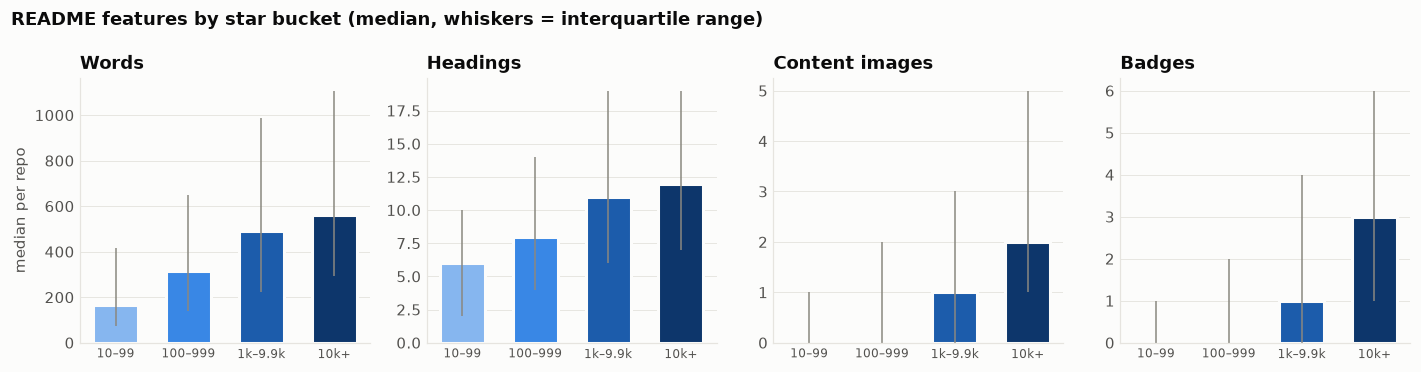

In [9]:
cols = {
    "readme_words": "Words",
    "readme_headings": "Headings",
    "readme_images": "Content images",
    "readme_badges": "Badges",
}
medians = software.groupby("bucket", observed=True)[list(cols)].median()
q1 = software.groupby("bucket", observed=True)[list(cols)].quantile(0.25)
q3 = software.groupby("bucket", observed=True)[list(cols)].quantile(0.75)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
x = np.arange(len(BUCKETS))
for ax, (col, title) in zip(axes, cols.items()):
    ax.bar(x, medians[col], color=[A.BUCKET_COLORS[b] for b in BUCKETS], width=0.62,
           edgecolor=A.SURFACE, linewidth=2)
    ax.errorbar(x, medians[col], yerr=[medians[col] - q1[col], q3[col] - medians[col]],
                fmt="none", ecolor=A.INK["muted"], elinewidth=1, capsize=0)
    ax.set_xticks(x, [LABEL[b] for b in BUCKETS], fontsize=8)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("median per repo")
fig.suptitle("README features by star bucket (median, whiskers = interquartile range)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
medians.rename(index=LABEL).round(0)

bucket,10–99,100–999,1k–9.9k,10k+
Install section,44.0,55.0,62.0,64.0
Usage / examples,36.0,44.0,46.0,37.0
Demo / screenshots section,6.0,8.0,11.0,14.0
Link to live demo or video,11.0,20.0,28.0,38.0
Contributing section,15.0,25.0,37.0,51.0
Licence section,21.0,33.0,37.0,43.0


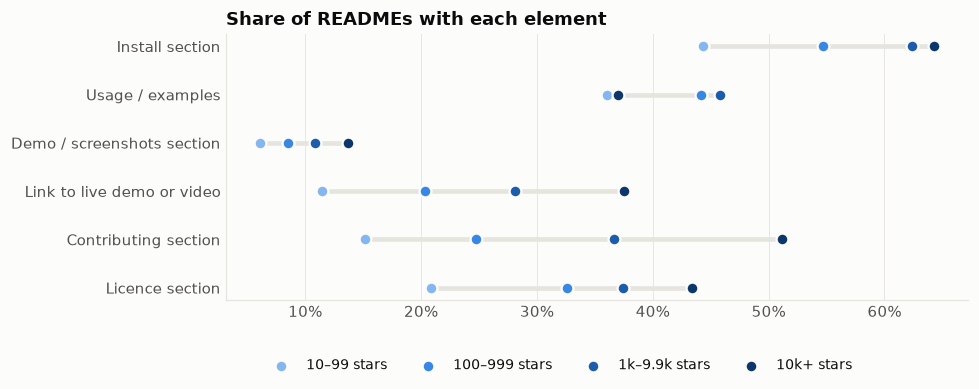

In [10]:
flags = {
    "has_install": "Install section",
    "has_usage": "Usage / examples",
    "has_demo_section": "Demo / screenshots section",
    "has_demo_link": "Link to live demo or video",
    "has_contributing": "Contributing section",
    "has_license_section": "Licence section",
}
prev = software.groupby("bucket", observed=True)[list(flags)].mean().T * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(flags))
ax.hlines(y, prev.min(axis=1), prev.max(axis=1), color=A.INK["grid"], linewidth=3)
for b in BUCKETS:
    ax.scatter(prev[b], y, s=60, color=A.BUCKET_COLORS[b], label=f"{LABEL[b]} stars",
               edgecolor=A.SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(y, flags.values())
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("Share of READMEs with each element")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.45, -0.32), fontsize=9)
fig.tight_layout()
prev.rename(index=flags, columns=LABEL).round(0)

Going up the buckets, READMEs get longer, use more headings and carry more badges. Contributing
and licence sections, and links to a live demo, become much more common. Install sections rise
slightly, and *usage* sections barely change. 10k+ READMEs are often short landing pages that
point to separate documentation.

Is this a strong relationship? The next cell compares two correlation measures for each
feature:

- **Overall** Spearman correlation with log(stars), across all four buckets.
- **Within-bucket** correlation: the average of the correlations computed inside each bucket.

The overall number benefits from the sample spanning four orders of magnitude of stars, so any
feature that differs between "tiny" and "huge" projects looks strongly correlated. The within-bucket
number asks a harder question: among repos of *similar* popularity, do the ones with richer READMEs
have more stars?

,overall,ci_low,ci_high,within_bucket,partial_age
feature,,,,,
Usage section,0.012,-0.018,0.043,0.007,0.013
Code blocks,0.085,0.053,0.114,0.031,0.089
Demo section,0.085,0.056,0.115,-0.021,0.088
GIFs,0.099,0.069,0.125,-0.002,0.102
Install section,0.152,0.120,0.181,0.021,0.156
Demo link,0.225,0.197,0.255,0.043,0.229
Contributing section,0.296,0.266,0.325,0.080,0.301
Headings,0.343,0.316,0.367,0.077,0.359
Content images,0.350,0.319,0.378,0.058,0.370


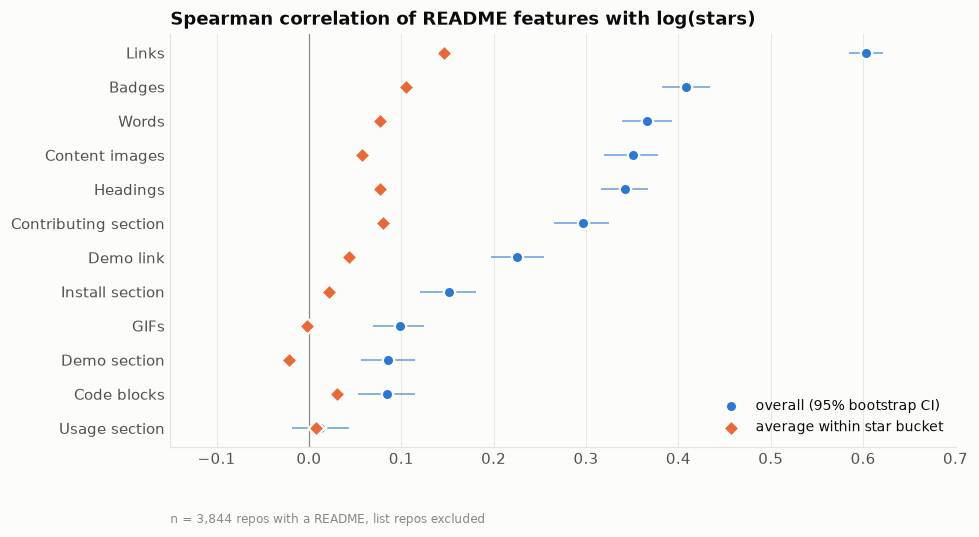

In [11]:
features = {
    "readme_links": "Links", "readme_badges": "Badges", "readme_words": "Words",
    "readme_images": "Content images", "readme_headings": "Headings", "has_contributing": "Contributing section",
    "has_demo_link": "Demo link", "has_install": "Install section", "readme_gifs": "GIFs",
    "readme_code_blocks": "Code blocks", "has_demo_section": "Demo section", "has_usage": "Usage section",
}
rows = []
for col, name in features.items():
    rho, lo, hi = A.spearman_ci(software[col].astype(float), software["log_stars"], n_boot=500)
    within = [stats.spearmanr(g[col].astype(float), g["log_stars"]).statistic
              for _, g in software.groupby("bucket", observed=True)]
    rows.append({"feature": name, "overall": rho, "ci_low": lo, "ci_high": hi,
                 "within_bucket": np.nanmean(within),
                 "partial_age": A.partial_spearman(software[col].astype(float), software["log_stars"],
                                                    software[["age_days"]])})
corr = pd.DataFrame(rows).sort_values("overall")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(corr))
ax.axvline(0, color=A.INK["muted"], linewidth=0.8)
ax.hlines(y, corr["ci_low"], corr["ci_high"], color=A.CATEGORICAL[0], linewidth=1.2, alpha=0.6)
ax.scatter(corr["overall"], y, s=55, color=A.CATEGORICAL[0], label="overall (95% bootstrap CI)",
           edgecolor=A.SURFACE, linewidth=1.5, zorder=3)
ax.scatter(corr["within_bucket"], y, s=55, color=A.CATEGORICAL[1], marker="D",
           label="average within star bucket", edgecolor=A.SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(y, corr["feature"])
ax.grid(axis="y", visible=False)
ax.set_xlim(-0.15, 0.7)
ax.set_title("Spearman correlation of README features with log(stars)")
ax.legend(loc="lower right", fontsize=9)
A.note(ax, f"n = {len(software):,} repos with a README, list repos excluded")
fig.tight_layout()
corr.set_index("feature").round(3)

**README richness separates tiny projects from big ones, but barely separates similar projects.**

- **Overall correlations are moderate.** Links (ρ ≈ 0.6), badges and words (≈ 0.4) and content
  images (≈ 0.35) all rise with stars.
- **Within a bucket the same correlations shrink to roughly 0.0–0.15.** Two repos with 1k–10k
  stars are not reliably distinguished by how long or illustrated their READMEs are.
- **Controlling for repo age** (the `partial_age` column) changes almost nothing, so this is not
  simply "older repos have longer READMEs".
- **GIFs, demo sections and usage sections show essentially no relationship** within buckets.

There is a plausible reverse effect too. Popular projects attract contributors who write better
docs, add CI badges and link to their documentation sites, so a rich README is at least partly a
*consequence* of popularity rather than a cause.

## 5. Activity: do popular repos keep working, and how many have stopped?

A repo counts as **inactive** if it is archived, has not been pushed to in 365 days, or had no
commits on its default branch in the last 52 weeks.

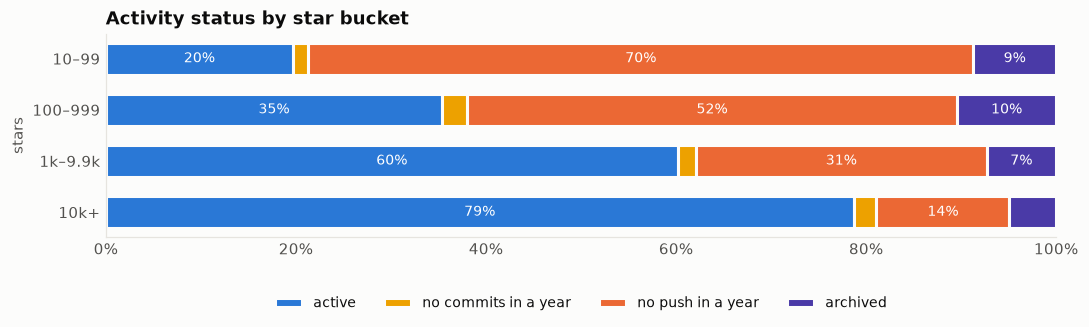

In [12]:
reason_order = ["active", "no commits in a year", "no push in a year", "archived"]
reason_colors = dict(zip(reason_order, [A.CATEGORICAL[0], A.CATEGORICAL[3], A.CATEGORICAL[1], A.CATEGORICAL[6]]))
reasons = pd.crosstab(repos["bucket"], repos["inactive_reason"], normalize="index")[reason_order] * 100

fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(reasons))
for reason in reason_order:
    vals = reasons[reason].to_numpy()
    ax.barh([LABEL[b] for b in reasons.index], vals, left=left, color=reason_colors[reason],
            edgecolor=A.SURFACE, linewidth=2, height=0.62, label=reason)
    for yi, (l, v) in enumerate(zip(left, vals)):
        if v >= 6:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if reason in ("active", "archived", "no push in a year") else A.INK["primary"])
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(visible=False)
ax.set_title("Activity status by star bucket")
ax.set_ylabel("stars")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.42), fontsize=9)
fig.tight_layout()

In [13]:
def inactive_estimate(mask):
    g = repos[mask]
    return pd.Series({"sample share": g["is_inactive"].mean(),
                      "population-weighted share": A.weighted_share(g["is_inactive"], g["weight"]),
                      "repos in population": g["weight"].sum()})

pd.DataFrame({
    "all repos (10+ stars)": inactive_estimate(repos["stars"] >= 10),
    "1,000+ stars": inactive_estimate(repos["bucket"].isin(["1k-10k", "10k+"])),
    "10,000+ stars": inactive_estimate(repos["bucket"] == "10k+"),
}).T.style.format({"sample share": "{:.0%}", "population-weighted share": "{:.0%}",
                   "repos in population": "{:,.0f}"})

,sample share,population-weighted share,repos in population
all repos (10+ stars),52%,80%,"2,610,140"
"1,000+ stars",31%,48%,"58,819"
"10,000+ stars",21%,28%,"4,948"


C:\Users\Pongo\AppData\Local\Temp\ipykernel_5620\3608195087.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data_box, vert=False, widths=0.5, patch_artist=True, showfliers=False,


,25%,50%,75%
bucket,,,
10–99,0.0,0.0,0.0
100–999,0.0,0.0,7.0
1k–9.9k,0.0,7.0,99.0
10k+,3.0,105.0,769.0


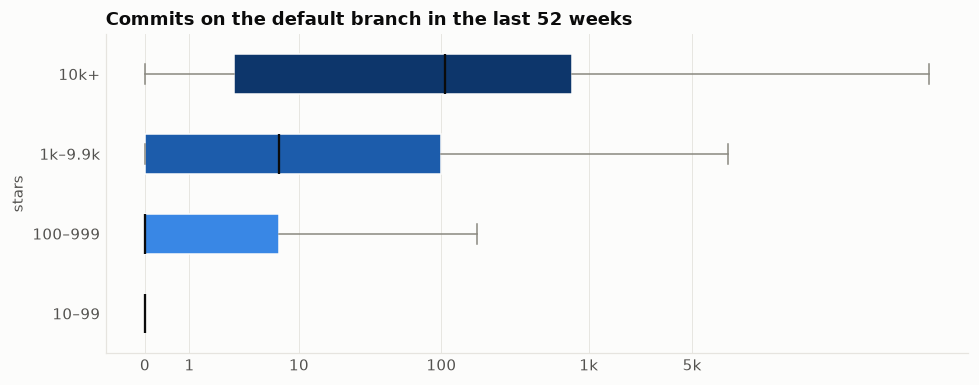

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
data_box = [np.log10(repos.loc[repos["bucket"] == b, "commits_52w"].dropna() + 1) for b in BUCKETS]
bp = ax.boxplot(data_box, vert=False, widths=0.5, patch_artist=True, showfliers=False,
                medianprops={"color": A.INK["primary"], "linewidth": 1.5},
                whiskerprops={"color": A.INK["muted"]}, capprops={"color": A.INK["muted"]})
for patch, b in zip(bp["boxes"], BUCKETS):
    patch.set(facecolor=A.BUCKET_COLORS[b], edgecolor=A.SURFACE)
ax.set_yticks(range(1, 5), [LABEL[b] for b in BUCKETS])
ax.set_xticks(np.log10(np.array([0, 1, 10, 100, 1000, 5000]) + 1), ["0", "1", "10", "100", "1k", "5k"])
ax.grid(axis="y", visible=False)
ax.set_title("Commits on the default branch in the last 52 weeks")
ax.set_ylabel("stars")
fig.tight_layout()
repos.groupby("bucket", observed=True)["commits_52w"].describe(percentiles=[.25, .5, .75])[["25%", "50%", "75%"]].rename(index=LABEL)

**Activity rises steeply with popularity, but a large share of popular repos have gone quiet.**

- **Commits:** the median 10k+ repo made about 100 commits in the past year. The median repo with
  fewer than 1,000 stars made none.
- **Inactive 10k+ repos:** about 21% of the 10k+ sample is inactive (27% after population
  weighting), and about 5% is formally archived.
- **Inactive 1k+ repos:** among all GitHub repos with **1,000+ stars**, an estimated **~48% are
  inactive**. Stars accumulate and never expire, so finished tools, tutorials, abandoned
  experiments and once-hyped projects keep their counts long after work stops.
- **Direction:** the relationship works both ways. Popular projects get issues and pull requests
  that keep them active, and active projects keep attracting stars.

## 6. Growth: how long does it take to reach 100, 1,000 and 10,000 stars?

Star dates come from GH Archive, because GitHub restricted its stargazer API in July 2026. Only
the **2,468 repos with a reliable star history** are used, meaning archive coverage between 0.5
and 1.5. Times are measured from the **first star**, which is a better proxy for when a repo went
public than its creation date: many repos are created privately and opened later.

,100 stars,"1,000 stars","10,000 stars"
count,2468.0,1615.0,811.0
10%,1.0,5.0,183.0
25%,10.0,76.0,538.0
50%,93.0,366.0,1111.0
75%,537.0,1016.0,2076.0
90%,1312.0,1938.0,2958.0


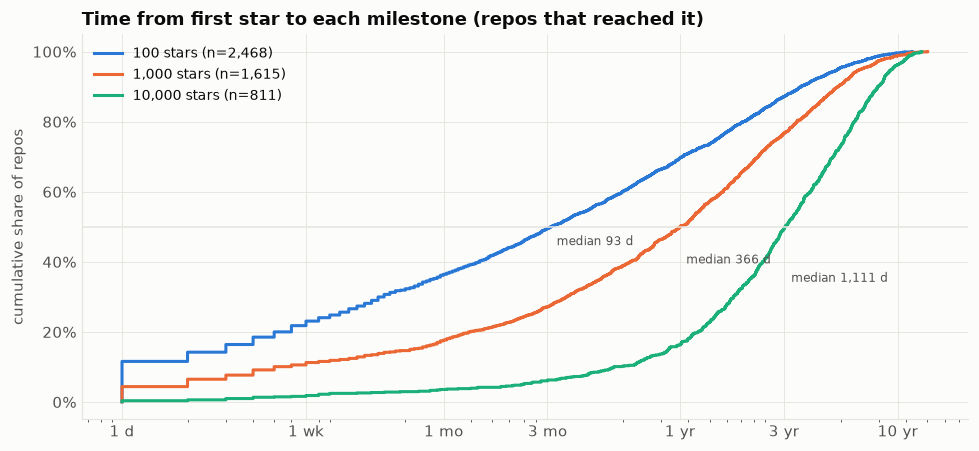

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, n in enumerate([100, 1000, 10000]):
    days = reliable.loc[reliable["stars"] >= n, f"days_to_{n}_from_first_star"].dropna()
    days = np.sort(days.clip(lower=1))
    ecdf = np.arange(1, len(days) + 1) / len(days)
    ax.step(days, ecdf * 100, where="post", color=A.CATEGORICAL[i], label=f"{n:,} stars (n={len(days):,})")
    med = np.median(days)
    ax.annotate(f"median {med:,.0f} d", xy=(med, 50), xytext=(4, -12 - 12 * i), textcoords="offset points",
                fontsize=8, color=A.INK["secondary"])
ax.set_xscale("log")
ax.set_xticks([1, 7, 30, 90, 365, 1095, 3650], ["1 d", "1 wk", "1 mo", "3 mo", "1 yr", "3 yr", "10 yr"])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.axhline(50, color=A.INK["grid"], linewidth=1)
ax.set_title("Time from first star to each milestone (repos that reached it)")
ax.set_ylabel("cumulative share of repos")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()

summary = pd.DataFrame({
    f"{n:,} stars": reliable.loc[reliable["stars"] >= n, f"days_to_{n}_from_first_star"].describe(
        percentiles=[.1, .25, .5, .75, .9])[["count", "10%", "25%", "50%", "75%", "90%"]]
    for n in [100, 1000, 10000]
})
summary.round(0)

Among repos that **did** reach each milestone, the typical (median) path was about **3 months to
100 stars, 1 year to 1,000 and 3 years to 10,000**. The spread is enormous. A tenth of the repos
that reached 1,000 did it within **5 days** of their first star, typically a launch that went
viral. Another tenth needed more than 5 years.

**A trap: "new repos grow faster".** A naive comparison by launch year suggests that repos
launched recently reach 1,000 stars much faster. That is a selection effect. A repo launched in
2025 can only appear in the 1k+ sample if it already got there, which means within less than two
years. To compare launch years fairly, the next cell looks only at launch years with at least
5 years of history, and only at repos that reached 1,000 within 5 years. Every cohort then had the
same window.

,repos,within_1_year,median_days
launch_year,,,
2012,54,0.22,935.0
2013,63,0.33,647.0
2014,95,0.38,593.0
2015,104,0.55,310.0
2016,103,0.47,405.0
2017,126,0.49,394.5
2018,117,0.50,345.0
2019,132,0.60,224.5
2020,131,0.56,251.0


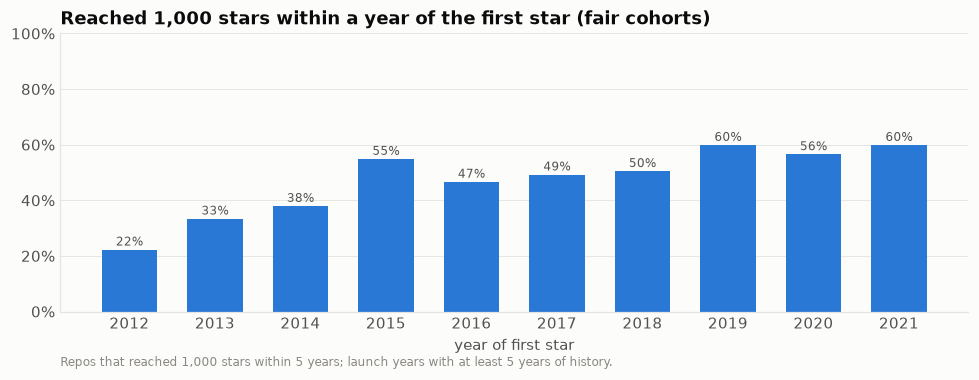

In [16]:
snapshot = pd.Timestamp(data.report["snapshot"])
big = reliable[reliable["stars"] >= 1000].copy()
big["launch_year"] = pd.to_datetime(big["first_star_date"]).dt.year
window = 5 * 365
fair = big[(snapshot - pd.to_datetime(big["first_star_date"])).dt.days >= window]
fair = fair[fair["days_to_1000_from_first_star"] <= window]
fast = fair.groupby("launch_year").agg(
    repos=("id", "size"),
    within_1_year=("days_to_1000_from_first_star", lambda s: (s <= 365).mean()),
    median_days=("days_to_1000_from_first_star", "median"),
)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(fast.index, fast["within_1_year"] * 100, color=A.CATEGORICAL[0], width=0.65)
for x, v, n in zip(fast.index, fast["within_1_year"] * 100, fast["repos"]):
    ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8, color=A.INK["secondary"])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.set_xticks(fast.index)
ax.set_title("Reached 1,000 stars within a year of the first star (fair cohorts)")
ax.set_xlabel("year of first star")
A.note(ax, "Repos that reached 1,000 stars within 5 years; launch years with at least 5 years of history.")
fig.tight_layout()
fast.round(2)

In [17]:
by_lang = fair.groupby("lang_group").agg(
    repos=("id", "size"),
    within_1_year=("days_to_1000_from_first_star", lambda s: (s <= 365).mean()),
    median_days=("days_to_1000_from_first_star", "median"),
).query("repos >= 20").sort_values("median_days")
by_lang.round(2)

,repos,within_1_year,median_days
lang_group,,,
JavaScript,92,0.64,240.0
TypeScript,78,0.55,255.5
Go,92,0.55,284.0
Python,94,0.55,285.0
Java,92,0.53,295.5
Other,97,0.53,311.0
Swift,65,0.48,375.0
Rust,75,0.47,425.0
PHP,61,0.43,432.0


With equal observation windows the trend is much gentler, though still real. Among repos that
reached 1,000 stars within five years, the share that did it within the first year rose from 22% of
2012 launches to about 60% of 2019–2021 launches. The median time fell from about 2.5 years to about
6–8 months. Larger audiences and social sharing probably explain part of this, but the change is far
smaller than the naive comparison suggests. By language, JavaScript projects reach 1,000 fastest
(median about 8 months), followed by TypeScript, Go and Python. C, C++, C# and Ruby are the slowest
(15–19 months). The groups are small (54–97 repos), so treat the language ranking as indicative
only.

How are the stars spread over a repo's life? The curves below follow 10k+ repos with a reliable
history and **at least 8 years since their first star**, so every curve covers the same 8 years.
Mixing younger repos into the same chart would make growth look artificially front-loaded,
because a 2-year-old repo is by definition at 100% of its stars after 2 years.

,median share of current stars (%)
months,
after 1 yr,8.0
after 2 yr,18.8
after 4 yr,45.4
after 6 yr,71.8
after 8 yr,89.5


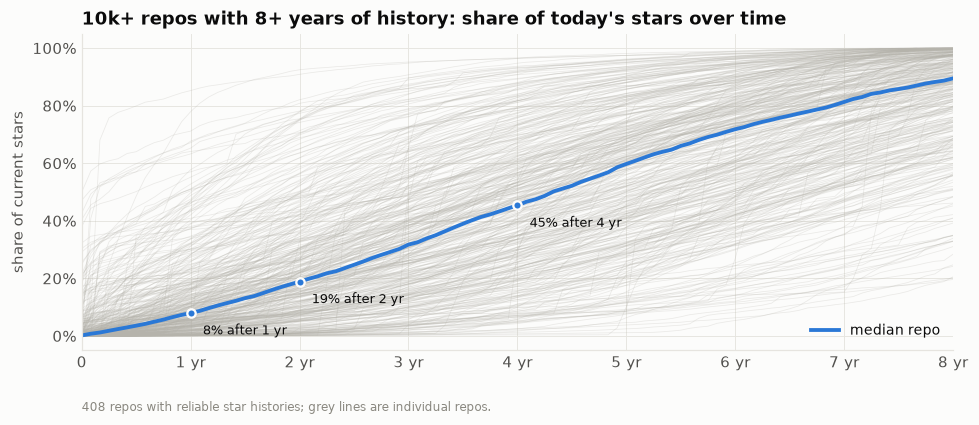

In [18]:
YEARS = 8
old_enough = reliable[(reliable["bucket"] == "10k+")
                      & ((snapshot - pd.to_datetime(reliable["first_star_date"])).dt.days >= YEARS * 365)]
m = data.monthly.merge(old_enough[["id", "first_star_date"]], on="id")
m["months"] = ((m["month"] - pd.to_datetime(m["first_star_date"]).dt.to_period("M").dt.to_timestamp())
               .dt.days / 30.44).round()
final = m.groupby("id")["stars_est"].transform("max")
m["share_of_final"] = m["stars_est"] / final * 100

fig, ax = plt.subplots(figsize=(9, 4))
for _, g in m.groupby("id"):
    ax.plot(g["months"], g["share_of_final"], color=A.MUTED, linewidth=0.5, alpha=0.25)
# Share reached by month k = the last monthly value at or before k (0 before the first star).
grid = range(0, YEARS * 12 + 1)
wide = m.pivot_table(index="months", columns="id", values="share_of_final").reindex(grid).ffill().fillna(0)
med = wide.median(axis=1)
ax.plot(med.index, med.values, color=A.CATEGORICAL[0], linewidth=2.5, label="median repo")
for yr in (1, 2, 4):
    v = med.loc[yr * 12]
    ax.annotate(f"{v:.0f}% after {yr} yr", xy=(yr * 12, v), xytext=(8, -14), textcoords="offset points",
                fontsize=8.5, color=A.INK["primary"])
    ax.scatter([yr * 12], [v], s=30, color=A.CATEGORICAL[0], zorder=4, edgecolor=A.SURFACE, linewidth=1.5)
ax.set_xlim(0, YEARS * 12)
ax.set_xticks(range(0, YEARS * 12 + 1, 12), [f"{y} yr" if y else "0" for y in range(0, YEARS + 1)])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title(f"10k+ repos with {YEARS}+ years of history: share of today's stars over time")
ax.set_ylabel("share of current stars")
ax.legend(loc="lower right", fontsize=9)
A.note(ax, f"{m['id'].nunique()} repos with reliable star histories; grey lines are individual repos.")
fig.tight_layout()
med.loc[[12, 24, 48, 72, 96]].rename(lambda k: f"after {k // 12} yr").round(1).to_frame("median share of current stars (%)")

**For long-lived popular repos, growth is steady rather than explosive.** The median 10k+ repo
with 8+ years of history had collected under a tenth of today's stars after its first year, about
a fifth after two years and under half after four. It keeps gaining stars at a fairly constant
pace for years. Viral launches exist (the fastest tenth of 1k+ repos reached 1,000 stars within
5 days), but they are the exception. One caveat: GH Archive's capture rate may have varied over
the years, which can bend individual curves.

## 7. Licences and topics

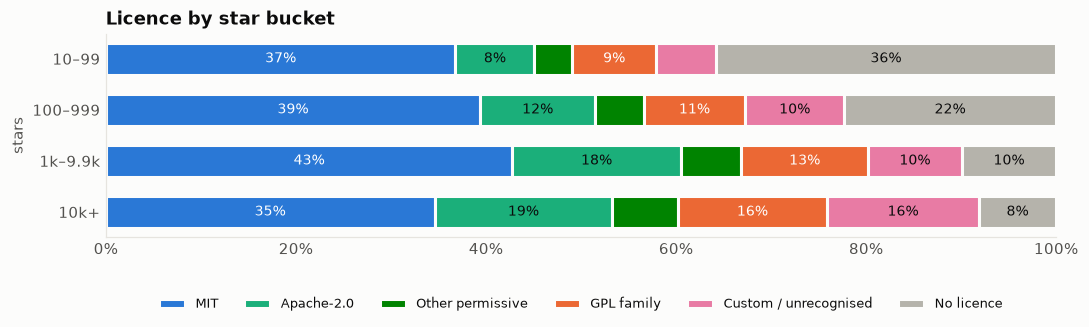

In [19]:
def licence_family(g):
    return {"MIT": "MIT", "Apache-2.0": "Apache-2.0", "GPL-3.0": "GPL family", "GPL-2.0": "GPL family",
            "AGPL-3.0": "GPL family", "LGPL": "GPL family", "Custom": "Custom / unrecognised",
            "None": "No licence"}.get(g, "Other permissive")

fam_order = ["MIT", "Apache-2.0", "Other permissive", "GPL family", "Custom / unrecognised", "No licence"]
fam_colors = dict(zip(fam_order, [A.CATEGORICAL[0], A.CATEGORICAL[2], A.CATEGORICAL[5],
                                  A.CATEGORICAL[1], A.CATEGORICAL[4], A.MUTED]))
fam = pd.crosstab(repos["bucket"], repos["license_group"].map(licence_family), normalize="index")[fam_order] * 100

fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(fam))
for f in fam_order:
    vals = fam[f].to_numpy()
    ax.barh([LABEL[b] for b in fam.index], vals, left=left, color=fam_colors[f], edgecolor=A.SURFACE,
            linewidth=2, height=0.62, label=f)
    for yi, (l, v) in enumerate(zip(left, vals)):
        if v >= 7:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if f in ("MIT", "GPL family") else A.INK["primary"])
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(visible=False)
ax.set_title("Licence by star bucket")
ax.set_ylabel("stars")
ax.legend(ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.42), fontsize=8.5)
fig.tight_layout()

**MIT is the default at every level of popularity.** The clearest difference is that **popular
repos almost always have a licence**: about 36% of 10–99 star repos have none, against about 8% of
10k+ repos. Apache-2.0 doubles from the bottom bucket to the top, which reflects company-backed
projects. Custom licences that GitHub cannot recognise (16% of 10k+) are often dual or
source-available licences. Copyleft (the GPL family, including AGPL) stays a minority everywhere.

Repos with at least one topic: {'10–99': '31%', '100–999': '50%', '1k–9.9k': '71%', '10k+': '82%'}


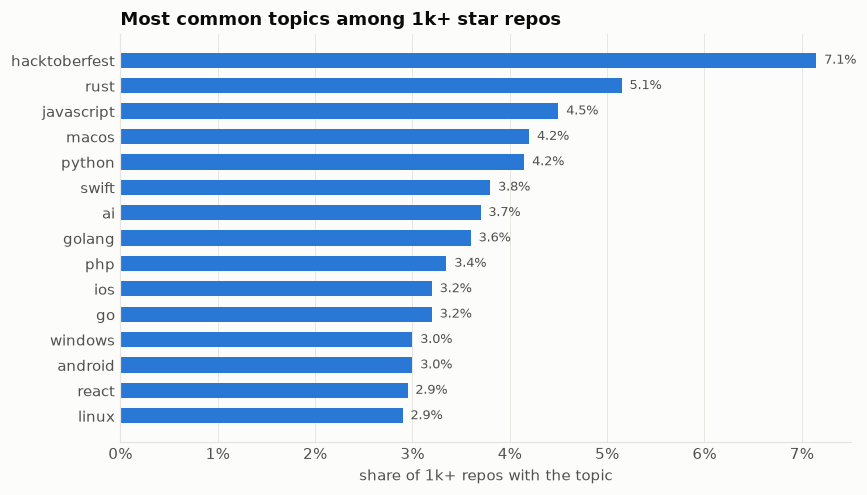

In [20]:
popular_ids = repos.loc[repos["bucket"].isin(["1k-10k", "10k+"]), "id"]
t_pop = data.topics[data.topics["id"].isin(popular_ids)]
top = (t_pop["topic"].value_counts().head(15) / len(popular_ids) * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=A.CATEGORICAL[0], height=0.6)
for y, v in enumerate(top.values):
    ax.text(v + 0.08, y, f"{v:.1f}%", va="center", fontsize=8.5, color=A.INK["secondary"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("Most common topics among 1k+ star repos")
ax.set_xlabel("share of 1k+ repos with the topic")
fig.tight_layout()
print("Repos with at least one topic:",
      repos.groupby("bucket", observed=True)["n_topics"].apply(lambda s: f"{(s > 0).mean():.0%}").rename(index=LABEL).to_dict())

,repos_2023_25,repos_2012_22,share_2023_25,share_2012_22,lift
topic,,,,,
llm,46.0,4.0,5.58,0.13,25.12
claude,17.0,0.0,2.06,0.00,21.61
claude-code,17.0,0.0,2.06,0.00,21.61
agentic-ai,14.0,0.0,1.70,0.00,17.97
llms,13.0,0.0,1.58,0.00,16.76
rag,12.0,0.0,1.45,0.00,15.55
codex,12.0,0.0,1.45,0.00,15.55
mcp,23.0,4.0,2.79,0.13,12.78
gemini,13.0,1.0,1.58,0.03,12.74


,repos_2023_25,repos_2012_22,share_2023_25,share_2012_22,lift
topic,,,,,
framework,3.0,34.0,0.36,1.07,0.40
javascript,11.0,106.0,1.33,3.34,0.42
hacktoberfest,19.0,164.0,2.30,5.17,0.46
mysql,4.0,35.0,0.48,1.10,0.49
kubernetes,4.0,33.0,0.48,1.04,0.51
ios,12.0,86.0,1.45,2.71,0.55
golang,12.0,85.0,1.45,2.68,0.56
cpp,6.0,41.0,0.73,1.29,0.59


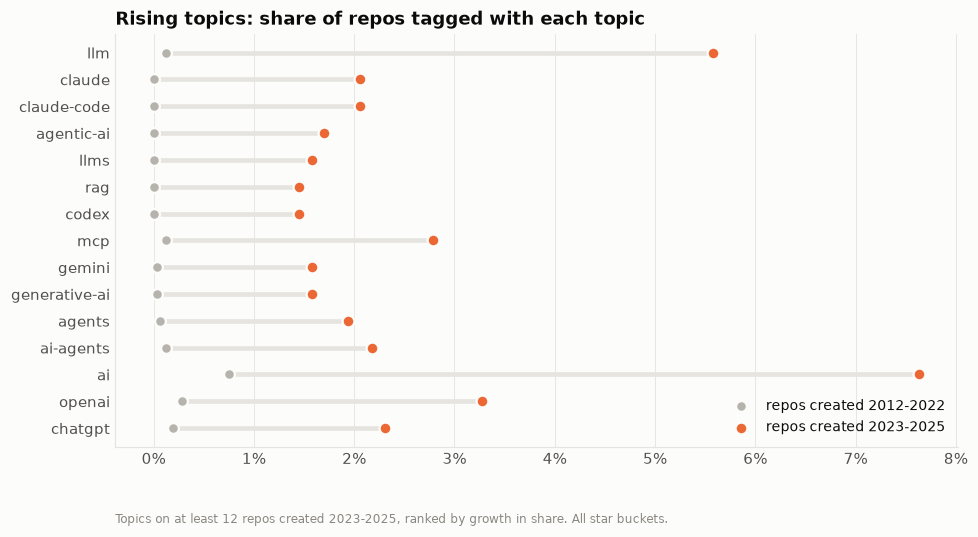

In [21]:
t = data.topics.merge(repos[["id", "created_year"]], on="id")
is_recent = repos["created_year"] >= 2023
n_recent, n_old = is_recent.sum(), (~is_recent).sum()
counts = pd.DataFrame({
    "repos_2023_25": t[t["created_year"] >= 2023]["topic"].value_counts(),
    "repos_2012_22": t[t["created_year"] < 2023]["topic"].value_counts(),
}).fillna(0)
counts["share_2023_25"] = counts["repos_2023_25"] / n_recent * 100
counts["share_2012_22"] = counts["repos_2012_22"] / n_old * 100
counts["lift"] = (counts["share_2023_25"] + 0.1) / (counts["share_2012_22"] + 0.1)
rising = counts[counts["repos_2023_25"] >= 12].sort_values("lift", ascending=False).head(15)
falling = counts[counts["repos_2012_22"] >= 30].sort_values("lift").head(8)

fig, ax = plt.subplots(figsize=(9, 5))
r = rising.iloc[::-1]
y = np.arange(len(r))
ax.hlines(y, r["share_2012_22"], r["share_2023_25"], color=A.INK["grid"], linewidth=3)
ax.scatter(r["share_2012_22"], y, s=50, color=A.MUTED, label="repos created 2012-2022", zorder=3,
           edgecolor=A.SURFACE, linewidth=1.5)
ax.scatter(r["share_2023_25"], y, s=60, color=A.CATEGORICAL[1], label="repos created 2023-2025", zorder=3,
           edgecolor=A.SURFACE, linewidth=1.5)
ax.set_yticks(y, r.index)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("Rising topics: share of repos tagged with each topic")
ax.legend(loc="lower right", fontsize=9)
A.note(ax, "Topics on at least 12 repos created 2023-2025, ranked by growth in share. All star buckets.")
fig.tight_layout()
display(rising.round(2))
falling.round(2)

Topics are used much more by popular repos (about 82% of 10k+ repos have at least one, against 31%
of 10–99 star repos), so they look like part of the same "well-maintained project" signal as a
licence and a homepage. Among 1k+ repos the most common topics are language and platform names
(rust, python, macos, ios...), plus `hacktoberfest`, a sign of projects that actively invite
contributors.

**The rising topics are all about AI.** Topics that barely existed before 2023, such as `llm`,
`mcp`, `ai-agents`, `agentic-ai`, `rag`, `claude-code` and `codex`, are each on 1.5–6% of repos
created in 2023–2025. The falling topics are mostly established ecosystems, such as `javascript`,
`golang`, `cpp`, `ios`, `kubernetes` and `mysql`. They are still very common, but they make up a
smaller share of new repos. `hacktoberfest` also fell, as that event's momentum faded.

## 8. Correlation overview

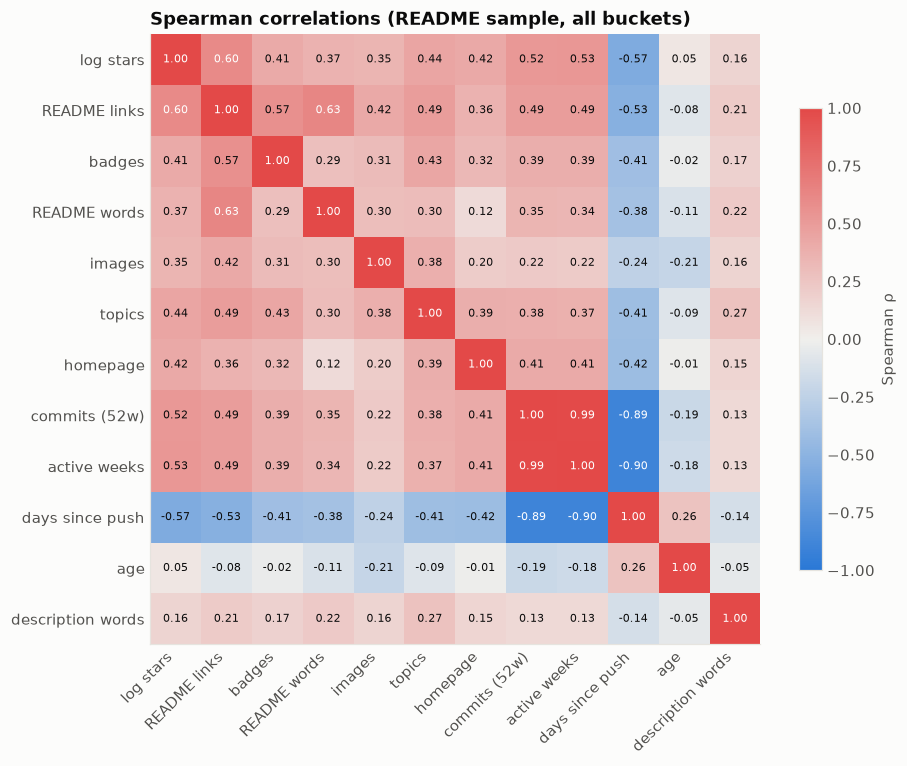

In [22]:
overview_cols = {
    "log_stars": "log stars", "readme_links": "README links", "readme_badges": "badges",
    "readme_words": "README words", "readme_images": "images", "n_topics": "topics",
    "has_homepage": "homepage", "commits_52w": "commits (52w)", "active_weeks_52": "active weeks",
    "days_since_push": "days since push", "age_days": "age", "description_words": "description words",
}
cm = software[list(overview_cols)].astype(float).corr(method="spearman").rename(index=overview_cols, columns=overview_cols)

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", list(A.DIVERGING))
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)), cm.columns, rotation=45, ha="right")
ax.set_yticks(range(len(cm)), cm.index)
ax.grid(visible=False)
for i in range(len(cm)):
    for j in range(len(cm)):
        v = cm.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.6 else A.INK["primary"])
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Spearman correlations (README sample, all buckets)")
fig.tight_layout()

The matrix shows that the "popularity signals" cluster together: READMEs with more links also have
more badges, more words and more images, and they tend to belong to repos with topics, a homepage
and recent commits. Because these features move together, the share of popularity that belongs to
any single one cannot be separated with descriptive statistics alone. Notebook `02_model.ipynb`
looks at them jointly.

## 9. Conclusions

1. **Languages.** Python and TypeScript dominate new popular repos: about 34% and 21% of 1k+ repos
   created in 2025, up from about 13% and 3% in 2012. JavaScript, Java, PHP and Ruby lost most of
   their share. Measured by hit rate (how often a repo with 10+ stars grows past 1,000), Rust, Go
   and TypeScript do best, at about twice the average.
2. **README.** Popular repos have longer, better-structured READMEs with more badges, links, images
   and contributing sections. Within the same star range, though, these features are only weakly
   related to stars (ρ ≤ 0.15), and GIFs or demo sections show no relationship at all. A good
   README looks like a *hygiene factor* that projects grow into, not a lever that produces stars.
3. **Activity.** The most popular repos are by far the most active (median about 100 commits a
   year for 10k+), yet an estimated **~48% of all 1k+ repos and ~27% of 10k+ repos are inactive**.
   Stars measure past attention, not current maintenance.
4. **Growth.** Repos that reach the milestones typically take about 3 months to reach 100 stars,
   1 year to 1,000 and 3 years to 10,000, with a huge spread: the fastest tenth reach 1,000 in
   under a week. For long-lived 10k+ repos, though, growth is steady: the median one had under half
   of today's stars four years after launch. After correcting for observation time, recent launches do reach 1,000 stars faster (about
   60% within a year for 2019–2021 launches, against 22% in 2012), though much less dramatically
   than a naive comparison suggests.
5. **Licences and topics.** Popular repos nearly always have a licence (mostly MIT or Apache-2.0)
   and use topics. The fastest-rising topics are about AI: LLMs, agents, MCP, RAG and AI coding
   tools.

## 10. Limitations

- **Correlation, not causation.** Many relationships plausibly run both ways. Popularity brings
  contributors, documentation, CI badges and commits as much as those things bring stars.
- **Sampling.** The sample is stratified by design. Population claims use census weights, but
  weights within a stratum assume that the repos drawn there are representative of it. Drawing
  from random date windows and result pages makes that likely, but the Search API's ranking is
  not documented.
- **Survivorship.** Only repos that still exist, are public and have 10+ stars are sampled.
  Deleted or private repos are invisible, and so is the long tail below 10 stars.
- **Snapshot.** Stars, activity and topics are measured once, on 8–10 October 2026. Features such
  as "README length" are today's README, not the README at the time the stars were earned.
- **API limits.** Commit activity covers only the default branch and the last 52 weeks.
  `pushed_at` counts pushes to any branch. Statistics were unavailable for 5 very large repos.
- **Star history.** Star dates come from GH Archive, not from GitHub, because the stargazer API is
  restricted. The archive misses some events and loses history across renames. Only histories with
  coverage between 0.5 and 1.5 are used, and milestone dates are coverage-corrected estimates.
- **Heuristics.** README sections, badge/decoration classification, the "list repo" flag and the
  inactivity rule are rules of thumb. They were checked on samples but will misclassify some repos.